In [12]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver

In [13]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [14]:
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [15]:
## Define the state
# in MessagesState there is a messages (variable) list that is used to store the conversation history.
class AgentState(MessagesState):
    next_agent:str #ehich agent should go next 

In [16]:
# Create simple tools
@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    # Using Tavily for web search
    search = TavilySearchResults(max_results=3)
    results = search.invoke(query)
    return str(results)

@tool
def write_summary(content: str) -> str:
    """Write a summary of the provided content."""
    # Simple summary generation
    summary = f"Summary of findings:\n\n{content[:500]}..."
    return summary

In [17]:
from langchain.chat_models import init_chat_model

llm=init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x73522d132850>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x73522d133250>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [18]:
# Define agent functions (simpler approach)
def researcher_agent(state: AgentState):
    """Researcher agent that searches for information"""
    
    messages = state["messages"]
    
    # Add system message for context
    system_msg = SystemMessage(content="You are a research assistant. Use the search_web tool to find information about the user's request.")
    
    # Call LLM with tools
    researcher_llm = llm.bind_tools([search_web])
    response = researcher_llm.invoke([system_msg] + messages)
    
    # Return the response and route to writer
    return {
        "messages": [response],
        "next_agent": "writer"
    }

In [19]:
def writer_agent(state: AgentState):
    """Writer agent that creates summaries"""
    
    messages = state["messages"]
    
    # Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and create a clear, concise summary of the findings.")
    
    # Simple completion without tools
    response = llm.invoke([system_msg] + messages)
    
    return {
        "messages": [response],
        "next_agent": "end"
    }

In [20]:
# Tool executor node
def execute_tools(state: AgentState):
    """Execute any pending tool calls"""
    messages = state["messages"]
    last_message = messages[-1]
    
    # Check if there are tool calls to execute
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        # Create tool node and execute
        tool_node = ToolNode([search_web, write_summary])
        response = tool_node.invoke(state)
        return response
    
    # No tools to execute
    return state

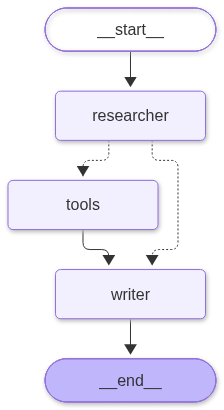

In [21]:
# Build graph
workflow = StateGraph(AgentState)

# Add nodes
workflow.add_node("researcher", researcher_agent)
workflow.add_node("tools", ToolNode([search_web, write_summary]))
workflow.add_node("writer", writer_agent)

# Route tool calls to the ToolNode, then send the tool result to the writer.
def route_researcher(state: AgentState):
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        return "tools"
    return "writer"

# Define flow
workflow.set_entry_point("researcher")
workflow.add_conditional_edges(
    "researcher",
    route_researcher,
    {"tools": "tools", "writer": "writer"},
)
workflow.add_edge("tools", "writer")
workflow.add_edge("writer", END)
final_workflow = workflow.compile()

final_workflow


In [22]:
response = final_workflow.invoke({
    "messages": [HumanMessage(content="Research the use cases of agentic AI in business")]
})

/tmp/ipykernel_205728/3356794159.py:6: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  search = TavilySearchResults(max_results=3)


In [26]:
response

{'messages': [HumanMessage(content='Research the use cases of agentic AI in business', additional_kwargs={}, response_metadata={}, id='172feed1-73ba-4e30-8102-5b255efeffcb'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to research use cases of agentic AI in business. Use search_web tool. Provide answer.', 'tool_calls': [{'id': 'fc_ee4cafd1-b854-4283-b88c-9745362e15b1', 'function': {'arguments': '{"query":"agentic AI business use cases"}', 'name': 'search_web'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 151, 'total_tokens': 201, 'completion_time': 0.051740674, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.013558453, 'prompt_tokens_details': None, 'queue_time': 0.003438535, 'total_time': 0.065299127}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e99e93f2ac', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}

In [27]:
from rich import print
print(response)

{
    'messages': [
        HumanMessage(
            content='Research the use cases of agentic AI in business',
            additional_kwargs={},
            response_metadata={},
            id='172feed1-73ba-4e30-8102-5b255efeffcb'
        ),
        AIMessage(
            content='',
            additional_kwargs={
                'reasoning_content': 'We need to research use cases of agentic AI in business. Use search_web tool.
Provide answer.',
                'tool_calls': [
                    {
                        'id': 'fc_ee4cafd1-b854-4283-b88c-9745362e15b1',
                        'function': {
                            'arguments': '{"query":"agentic AI business use cases"}',
                            'name': 'search_web'
                        },
                        'type': 'function'
                    }
                ]
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 50,
                    'prompt_tokens': 151,
                    'total_tokens': 201,
                    'completion_time': 0.051740674,
                    'completion_tokens_details': {'reasoning_tokens': 22},
                    'prompt_time': 0.013558453,
                    'prompt_tokens_details': None,
                    'queue_time': 0.003438535,
                    'total_time': 0.065299127
                },
                'model_name': 'openai/gpt-oss-20b',
                'system_fingerprint': 'fp_e99e93f2ac',
                'service_tier': 'on_demand',
                'finish_reason': 'tool_calls',
                'logprobs': None,
                'model_provider': 'groq'
            },
            id='lc_run--01a21e42-6abf-7d01-a9b7-4312afa81c8e-0',
            tool_calls=[
                {
                    'name': 'search_web',
                    'args': {'query': 'agentic AI business use cases'},
                    'id': 'fc_ee4cafd1-b854-4283-b88c-9745362e15b1',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 151,
                'output_tokens': 50,
                'total_tokens': 201,
                'output_token_details': {'reasoning': 22}
            }
        ),
        ToolMessage(
            content="[{'title': 'Top 10 Real-World Use Cases of Agentic AI Transforming Business', 'url': 
'https://www.linkedin.com/pulse/top-10-real-world-use-cases-agentic-ai-transforming-business-bhavsar-7sbjf', 
'content': '## 3. Workflow Orchestration Across Departments\\n\\nOne of the strongest use cases of Agentic AI is 
workflow automation. These agents act as coordinators, connecting HR, finance, and operations without manual 
effort. Imagine an AI agent that automatically approves expense requests, updates payroll, and notifies 
employees—all while following company compliance rules. This level of autonomous orchestration reduces errors and 
speeds up decision-making.\\n\\n## 4. Market Research & Competitive Intelligence\\n\\nEnterprises no longer rely 
solely on manual research. Agentic AI agents can scan competitor websites, monitor industry news, and analyze 
customer feedback in real time. A retail business, for example, can track competitor pricing trends daily, helping 
them adjust their own strategy instantly. [...] ### 1. AI-Powered Customer Support Agents\\n\\nBusinesses are 
adopting Agentic AI to transform customer service. Unlike rule-based chatbots, these agents understand context, 
maintain conversations across channels, and deliver personalized resolutions. In eCommerce, for example, AI agents 
handle returns, track orders, and answer complex queries instantly—cutting response times while boosting customer 
satisfaction.\\n\\n## 2. Sales & Lead Qualification Automation\\n\\nSales teams often waste hours sorting through 
unqualified leads. With Agentic AI, enterprises deploy intelligent agents that score

In [28]:
print(response["messages"][-1].content)

**Agentic AI Use‑Cases in Business – Key Findings**

| Domain | Typical Agentic AI Function | Business Value |
|--------|---------------------------|----------------|
| **Customer Experience** | • Conversational agents that understand context, maintain multi‑channel threads, and 
resolve complex queries (e.g., returns, order tracking). <br>• Personalized shopping assistants (Walmart, 
e‑commerce) that recommend products and handle checkout. | • 24/7 support, reduced response times, higher CSAT. |
| **Sales & Lead Management** | • Autonomous lead scoring, personalized outreach, and meeting scheduling. <br>• 
End‑to‑end qualification pipelines that hand off only high‑value prospects. | • Faster sales cycles, higher 
conversion rates, more efficient reps. |
| **Workflow & Process Automation** | • AI orchestrators that coordinate across HR, finance, operations, and 
compliance (e.g., expense approval → payroll → notification). <br>• End‑to‑end business workflows that trigger 
actions without human hand‑off. | • Lower error rates, compliance adherence, speedier decision making. |
| **Market Intelligence** | • Continuous scanning of competitor sites, news feeds, and social sentiment to adjust 
pricing or product strategy in real time. | • Agile strategy adjustments, competitive edge. |
| **Supply Chain & Inventory** | • Demand forecasting, supplier communication, and automatic restocking triggers. 
<br>• Inventory optimization to avoid stockouts or overstock. | • Cost savings, improved service levels. |
| **Fraud & Risk Management** | • Real‑time transaction monitoring, anomaly detection, and automated alerts for 
financial institutions. <br>• Continuous compliance audits and KYC verification. | • Reduced fraud losses, lower 
false‑positive rates, regulatory compliance. |
| **Human Resources** | • AI agents for onboarding, benefits enrollment, employee file management, and payroll 
validation. | • Faster hires, reduced manual HR workload, improved employee self‑service. |
| **Finance & Accounting** | • Invoice data extraction, matching, validation, and payment cycle acceleration. <br>•
Automated loan approvals and legal‑compliance checks. | • Time savings, accuracy, faster cash flow. |
| **Knowledge Management** | • Intelligent assistants that retrieve, curate, and surface relevant information for 
employees. | • Faster decision making, reduced knowledge silos. |

**Takeaway**

Agentic AI—AI systems that can autonomously complete multi‑step workflows, make decisions, and execute actions—has 
moved beyond rule‑based chatbots. Across retail, finance, HR, and operations, it delivers measurable gains in 
speed, accuracy, compliance, and customer satisfaction. Companies that deploy such agents typically see **30‑50 % 
reductions in manual effort** and **significant improvements in key metrics** such as conversion rates, CSAT, and 
compliance audit scores.